# A/B Test: Cookie Cats Gate Placement

In this project, I analyze an A/B test from the mobile game Cookie Cats. The game moves players through levels, and at some point a "gate" forces them to wait or pay before continuing. The team tested moving the first gate from level 30 (`gate_30`) to level 40 (`gate_40`).

**Business question:** Does moving the gate change player retention?

**Data:** Cookie Cats A/B testing dataset from Kaggle (90,189 players).

**Plan:** (1) check the data, (2) compare the two groups, (3) run statistical tests, (4) make a recommendation.

## 1. Load the Data

First, I load the data and check its size, missing values, and how many players are in each group.

In [9]:
import pandas as pd

df = pd.read_csv("../data/cookie_cats.csv")
print(df.shape)
print(df.head())
print(df.isna().sum())
print(df["version"].value_counts())

(90189, 5)
   userid  version  sum_gamerounds  retention_1  retention_7
0     116  gate_30               3        False        False
1     337  gate_30              38         True        False
2     377  gate_40             165         True        False
3     483  gate_40               1        False        False
4     488  gate_40             179         True         True
userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64
version
gate_40    45489
gate_30    44700
Name: count, dtype: int64


## 2. Data Quality Checks

Before comparing the groups, I check for duplicate users, extreme values, and players who never played.

In [10]:
# Check duplicate users
print("Duplicate userids:", df["userid"].duplicated().sum())

# Distribution of game rounds
print(df["sum_gamerounds"].describe())

# Look at the largest values (possible outliers)
print(df["sum_gamerounds"].sort_values(ascending=False).head(10))

# Players who never played after installing
print("Zero-round players:", (df["sum_gamerounds"] == 0).sum())

Duplicate userids: 0
count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64
57702    49854
7912      2961
29417     2640
43671     2438
48188     2294
46344     2251
87007     2156
36933     2124
88328     2063
6536      2015
Name: sum_gamerounds, dtype: int64
Zero-round players: 3994


**What I found:**
- There are no duplicate users and no missing values.
- One player has 49,854 game rounds, while the next highest is 2,961. This is clearly an outlier, so I remove it before the analysis.
- 3,994 players have zero rounds. I keep them, because they are real users who installed the game and did not play.
- The two groups are close in size (44,700 vs 45,489), so the randomization looks reasonable.

## 3. Compare the Two Groups

Here I compare retention and game rounds between `gate_30` and `gate_40`.

In [11]:
summary = df.groupby("version").agg(
    users=("userid", "count"),
    retention_1=("retention_1", "mean"),
    retention_7=("retention_7", "mean"),
    mean_rounds=("sum_gamerounds", "mean"),
    median_rounds=("sum_gamerounds", "median"),
)
print(summary)

         users  retention_1  retention_7  mean_rounds  median_rounds
version                                                             
gate_30  44700     0.448188     0.190201    52.456264           17.0
gate_40  45489     0.442283     0.182000    51.298776           16.0


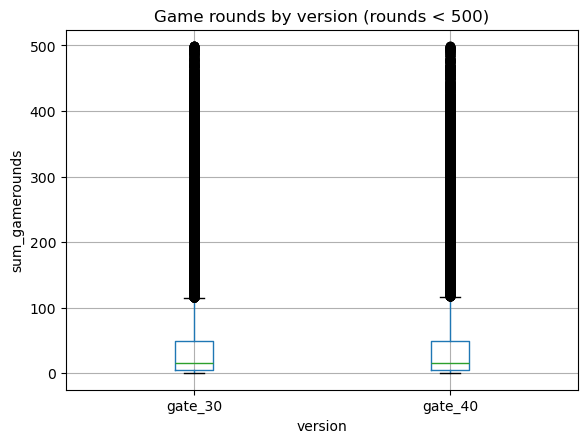

In [12]:
import matplotlib.pyplot as plt

# Exclude the extreme outlier so the plot is readable
plot_df = df[df["sum_gamerounds"] < 500]

plot_df.boxplot(column="sum_gamerounds", by="version")
plt.title("Game rounds by version (rounds < 500)")
plt.suptitle("")
plt.ylabel("sum_gamerounds")
plt.show()

**What I see:**
- The mean number of rounds (about 52) is much higher than the median (16 or 17), so the data is right-skewed. A small group of heavy players pulls the mean up.
- The boxplots of the two groups look almost identical.
- `gate_30` has slightly higher retention: 1-day retention is 44.8% vs 44.2%, and 7-day retention is 19.0% vs 18.2%.
- The differences are small. I need a statistical test to tell whether they are real or just random noise.

In [13]:
# Remove the extreme outlier (49,854 rounds)
df_clean = df[df["sum_gamerounds"] < 10000].copy()
print("Rows removed:", len(df) - len(df_clean))
print(df_clean.shape)

Rows removed: 1
(90188, 5)


## 4. Hypothesis Testing

Retention is a yes/no outcome, so I compare the proportion of retained players between the two groups using a two-proportion z-test.

- **H0:** The retention rate is the same for `gate_30` and `gate_40`.
- **H1:** The retention rates are different.
- Significance level: 0.05

In [14]:
from statsmodels.stats.proportion import proportions_ztest

for metric in ["retention_1", "retention_7"]:
    g30 = df_clean[df_clean["version"] == "gate_30"][metric]
    g40 = df_clean[df_clean["version"] == "gate_40"][metric]

    counts = [g30.sum(), g40.sum()]
    nobs = [len(g30), len(g40)]

    z, p = proportions_ztest(counts, nobs)
    diff = g30.mean() - g40.mean()

    print(f"{metric}: diff (gate_30 - gate_40) = {diff:.4f}, z = {z:.3f}, p-value = {p:.4f}")

retention_1: diff (gate_30 - gate_40) = 0.0059, z = 1.787, p-value = 0.0739
retention_7: diff (gate_30 - gate_40) = 0.0082, z = 3.157, p-value = 0.0016


**Results:**

| Metric | Difference (gate_30 − gate_40) | z | p-value |
|---|---|---|---|
| 1-day retention | 0.59 pp | 1.787 | 0.0739 |
| 7-day retention | 0.82 pp | 3.157 | 0.0016 |

- For 1-day retention, p = 0.074 is above 0.05, so I cannot say the two versions are different.
- For 7-day retention, p = 0.0016 is below 0.05, so the difference is statistically significant. Players who saw the gate at level 30 are more likely to come back after a week.
- I tested two metrics, so I also checked a stricter threshold (0.05 / 2 = 0.025). The 7-day result still passes.

## 5. Bootstrap Check (7-day Retention)

As a second check, I use bootstrapping. I resample each group with replacement 2,000 times, calculate the difference in 7-day retention each time, and look at the distribution of these differences. If the 95% confidence interval does not include 0, it supports the z-test result.

Mean difference: 0.0082
95% CI: [0.0033, 0.0128]
Share of bootstrap samples where gate_30 > gate_40: 1.000


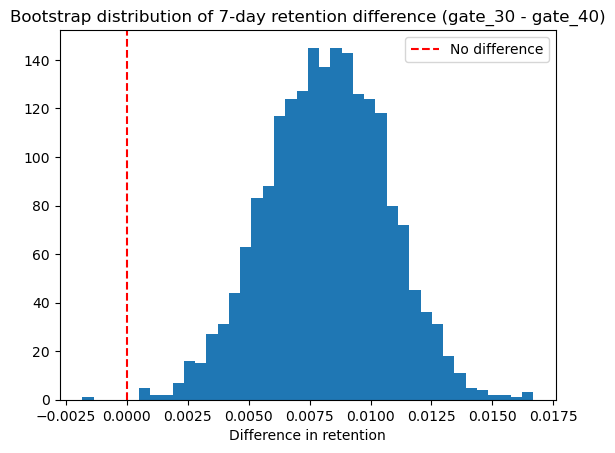

In [15]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

g30 = df_clean[df_clean["version"] == "gate_30"]["retention_7"].astype(int).values
g40 = df_clean[df_clean["version"] == "gate_40"]["retention_7"].astype(int).values

boot_diffs = []
for _ in range(2000):
    s30 = np.random.choice(g30, size=len(g30), replace=True).mean()
    s40 = np.random.choice(g40, size=len(g40), replace=True).mean()
    boot_diffs.append(s30 - s40)

boot_diffs = np.array(boot_diffs)
ci_low, ci_high = np.percentile(boot_diffs, [2.5, 97.5])

print(f"Mean difference: {boot_diffs.mean():.4f}")
print(f"95% CI: [{ci_low:.4f}, {ci_high:.4f}]")
print(f"Share of bootstrap samples where gate_30 > gate_40: {(boot_diffs > 0).mean():.3f}")

plt.hist(boot_diffs, bins=40)
plt.axvline(0, color="red", linestyle="--", label="No difference")
plt.title("Bootstrap distribution of 7-day retention difference (gate_30 - gate_40)")
plt.xlabel("Difference in retention")
plt.legend()
plt.show()

**Bootstrap results:**
- The mean difference in 7-day retention is 0.82 percentage points, which matches the z-test.
- The 95% confidence interval is [0.33, 1.28] percentage points. It does not include 0.
- In almost all of the 2,000 bootstrap samples (1,999 out of 2,000), `gate_30` had higher retention than `gate_40`.
- This supports the z-test result: the higher 7-day retention for `gate_30` is unlikely to be random noise.

## 6. Conclusion and Recommendation

**Result:** Moving the gate from level 30 to level 40 did not improve retention. 1-day retention shows no significant difference (p = 0.074), and 7-day retention is significantly *lower* for `gate_40` (p = 0.0016; bootstrap 95% CI for the difference: 0.33 to 1.28 percentage points).

**Recommendation:** Keep the gate at level 30.

**How big is the effect?** The difference is about 0.8 percentage points, or roughly a 4.5% relative drop in 7-day retention for `gate_40`. The test is significant partly because the sample is large (about 90,000 players). Whether this matters in practice depends on how much value a retained player brings, which is not in this dataset.

**Limitations:**
- I only looked at retention. Revenue and in-app purchases are not in the data, but they matter for a real decision.
- I do not know how players were assigned to the two groups, so I assume the assignment was random.
- This is one test over one period, so I cannot say whether the result would hold at other times.
- I removed one extreme outlier (49,854 rounds) and did not change any other data.

**What I would do next:** Check whether the gate also affects revenue, and test other gate positions (for example level 20 or 50).